In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/questions.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2analysis_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/cid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_window_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/test.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/kc_routes_map.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv


In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm   # thêm dòng này

# 1. Config


In [3]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",
    "num_concepts": 865,
    "input_dim": 100,
    "hidden_dim": 200,
    "dropout": 0.2,
    "lr": 1e-3,
    "batch_size": 100,
    "num_epochs": 100,
    "patience": 10,
    "save_path": "/kaggle/working/checkpoint"
}

# 2. Data Loading

In [4]:
df_train_valid = pd.read_csv(config['data_train_valid_path'])
df_test = pd.read_csv(config['data_test_path'])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset & DataLoader

In [5]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DKTDataset(Dataset):
    def __init__(self, df, num_concepts, fold=None, is_train=True):

        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold] 
        
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks= [parse_seq(x) for x in df['selectmasks']]

        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )
        self.num_concepts = num_concepts
        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }
        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)
        return item

        

# 4. Model Definition

In [6]:
class DKT(nn.Module):
    def __init__(self, num_concepts, embed_dim=100, hidden_dim=200, dropout=0.2):
        super().__init__()
        self.num_concepts = num_concepts
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.interaction_emb = nn.Embedding(self.num_concepts * 2, self.embed_dim)
        self.lstm_layer = nn.LSTM(self.embed_dim, self.hidden_dim, batch_first=True)
        self.dropout_layer = nn.Dropout(dropout)
        self.out_layer = nn.Linear(self.hidden_dim, self.num_concepts)
    def forward(self, c, r):
        x = c + self.num_concepts * r
        xemb = self.interaction_emb(x)
        h, _ = self.lstm_layer(xemb)
        h = self.dropout_layer(h)
        y = self.out_layer(h)
        return y

# 5. Compute Metric

In [7]:
from collections import defaultdict
import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score, mean_squared_error, mean_absolute_error, f1_score, precision_score, recall_score

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_binary = (y_pred > 0.5).astype(int)

    if len(np.unique(y_true)) > 1:
        auc = roc_auc_score(y_true, y_pred)
    else:
        auc = 0.5

    acc = accuracy_score(y_true, y_pred_binary)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)
    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    recall = recall_score(y_true, y_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "mae": mae,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# 6. Train Loop

In [8]:
import torch.nn.functional as F

def train_epoch(model, train_loader, valid_loader, optimizer, device, num_epochs=20, patience=5):
    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # ---------------- TRAIN ----------------
        model.train()
        total_loss = 0.0
        n_batches = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(concepts, responses)        # (B, T, num_concepts)
            probs = torch.sigmoid(logits)

            # ---- FIX: shift để tránh leakage ----
            pred = probs[:, :-1, :]
            next_concepts = concepts[:, 1:]
            next_responses = responses[:, 1:].float()
            next_mask = selectmasks[:, 1:]

            pred_selected = torch.gather(
                pred, 2, next_concepts.unsqueeze(-1)
            ).squeeze(-1)

            valid = next_mask == 1
            loss = F.binary_cross_entropy(
                pred_selected[valid], next_responses[valid]
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            n_batches += 1
            pbar.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / n_batches
        train_loss_history.append(avg_train_loss)

        # ---------------- VALID ----------------
        model.eval()
        val_total_loss = 0.0
        val_batches = 0
        with torch.no_grad():
            for batch in valid_loader:
                concepts = batch["concepts"].to(device)
                responses = batch["responses"].to(device)
                selectmasks = batch["selectmasks"].to(device)

                logits = model(concepts, responses)
                probs = torch.sigmoid(logits)

                pred = probs[:, :-1, :]
                next_concepts = concepts[:, 1:]
                next_responses = responses[:, 1:].float()
                next_mask = selectmasks[:, 1:]

                pred_selected = torch.gather(
                    pred, 2, next_concepts.unsqueeze(-1)
                ).squeeze(-1)

                valid_mask = next_mask == 1
                v_loss = F.binary_cross_entropy(
                    pred_selected[valid_mask], next_responses[valid_mask]
                )
                val_total_loss += v_loss.item()
                val_batches += 1

        avg_val_loss = val_total_loss / val_batches
        valid_loss_history.append(avg_val_loss)

        val_metrics = evaluate(model, valid_loader, device, question_level=False)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # ---------------- EARLY STOPPING ----------------
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break

    # load lại best checkpoint theo val AUC
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }
    return model, history

# 7. Evaluate

In [9]:
def evaluate(model, loader, device, question_level=True):
    model.eval()

    if question_level:
        preds = defaultdict(list)
        labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset không có 'qidxs' nên không thể eval ở mức question.")

            logits = model(concepts, responses)          # (B, T, num_concepts)
            probs = torch.sigmoid(logits)

            # ---- shift để tránh leakage: h[t] dự đoán response tại t+1 ----
            pred = probs[:, :-1, :]                       # (B, T-1, num_concepts)
            next_concepts = concepts[:, 1:]               # concept thực ở bước kế tiếp
            next_responses = responses[:, 1:].float()     # đúng/sai thực ở bước kế tiếp
            next_mask = selectmasks[:, 1:]                # mask tương ứng (bỏ bước đầu)

            pred_selected = torch.gather(
                pred, 2, next_concepts.unsqueeze(-1)
            ).squeeze(-1)                                  # (B, T-1)

            if question_level:
                qidxs = batch["qidxs"][:, 1:]              # cũng phải shift giống next_mask
                pred_cpu = pred_selected.cpu()
                target_cpu = next_responses.cpu()
                mask_cpu = next_mask.cpu()
                qid_cpu = qidxs.cpu()

                B, Tm1 = pred_cpu.shape
                for i in range(B):
                    for t in range(Tm1):
                        if mask_cpu[i, t] == 1:
                            qid = qid_cpu[i, t].item()
                            preds[qid].append(pred_cpu[i, t].item())
                            labels[qid].append(target_cpu[i, t].item())
            else:
                valid = next_mask == 1
                all_preds.extend(pred_selected[valid].cpu().numpy().tolist())
                all_labels.extend(next_responses[valid].cpu().numpy().tolist())

    if question_level:
        final_pred, final_true = [], []
        for k in preds:
            final_pred.append(sum(preds[k]) / len(preds[k]))          # trung bình dự đoán của mọi lần xuất hiện qid k
            final_true.append(round(sum(labels[k]) / len(labels[k]))) # trung bình nhãn thực (thường sẽ giống nhau cho cùng 1 qid)
        return compute_metrics(final_true, final_pred)
    else:
        return compute_metrics(all_labels, all_preds)

# 8. Training & Evaluating


FOLD 0


Epoch 1: train_loss=0.4269, val_loss=0.3846, val_auc=0.8153, val_acc=0.8345


Epoch 2: train_loss=0.3789, val_loss=0.3750, val_auc=0.8250, val_acc=0.8380


Epoch 3: train_loss=0.3720, val_loss=0.3713, val_auc=0.8287, val_acc=0.8392


Epoch 4: train_loss=0.3680, val_loss=0.3693, val_auc=0.8310, val_acc=0.8399


...

Epoch 16: train_loss=0.3448, val_loss=0.3663, val_auc=0.8340, val_acc=0.8408


Epoch 17: train_loss=0.3430, val_loss=0.3670, val_auc=0.8335, val_acc=0.8403


Epoch 18: train_loss=0.3412, val_loss=0.3676, val_auc=0.8329, val_acc=0.8403


Epoch 19: train_loss=0.3397, val_loss=0.3686, val_auc=0.8325, val_acc=0.8400


Epoch 20: train_loss=0.3382, val_loss=0.3697, val_auc=0.8318, val_acc=0.8399
Early stopping tại epoch 20


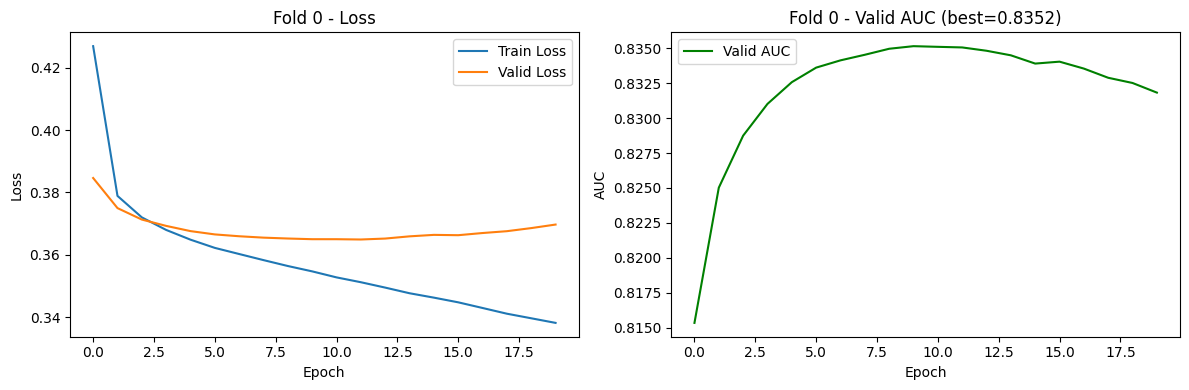

Fold 0 xong. Best valid AUC = 0.8352

FOLD 1


Epoch 1: train_loss=0.4275, val_loss=0.3830, val_auc=0.8167, val_acc=0.8355


Epoch 2: train_loss=0.3796, val_loss=0.3730, val_auc=0.8259, val_acc=0.8391


Epoch 3: train_loss=0.3725, val_loss=0.3696, val_auc=0.8294, val_acc=0.8405


Epoch 4: train_loss=0.3684, val_loss=0.3673, val_auc=0.8317, val_acc=0.8411


...

Epoch 16: train_loss=0.3452, val_loss=0.3647, val_auc=0.8346, val_acc=0.8415


Epoch 17: train_loss=0.3436, val_loss=0.3650, val_auc=0.8339, val_acc=0.8413


Epoch 18: train_loss=0.3419, val_loss=0.3658, val_auc=0.8335, val_acc=0.8413


Epoch 19: train_loss=0.3403, val_loss=0.3665, val_auc=0.8331, val_acc=0.8408


Epoch 20: train_loss=0.3386, val_loss=0.3673, val_auc=0.8322, val_acc=0.8411
Early stopping tại epoch 20


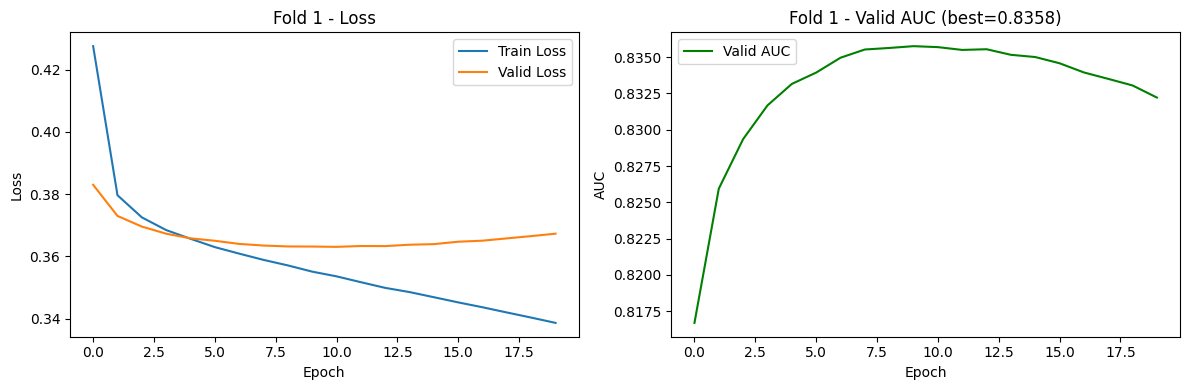

Fold 1 xong. Best valid AUC = 0.8358

FOLD 2


Epoch 1: train_loss=0.4266, val_loss=0.3847, val_auc=0.8203, val_acc=0.8327


Epoch 2: train_loss=0.3789, val_loss=0.3760, val_auc=0.8290, val_acc=0.8366


Epoch 3: train_loss=0.3720, val_loss=0.3715, val_auc=0.8328, val_acc=0.8382


Epoch 4: train_loss=0.3681, val_loss=0.3694, val_auc=0.8348, val_acc=0.8390


...

Epoch 16: train_loss=0.3452, val_loss=0.3664, val_auc=0.8380, val_acc=0.8397


Epoch 17: train_loss=0.3435, val_loss=0.3669, val_auc=0.8374, val_acc=0.8397


Epoch 18: train_loss=0.3421, val_loss=0.3676, val_auc=0.8363, val_acc=0.8393


Epoch 19: train_loss=0.3404, val_loss=0.3685, val_auc=0.8364, val_acc=0.8395


Epoch 20: train_loss=0.3387, val_loss=0.3689, val_auc=0.8352, val_acc=0.8391
Early stopping tại epoch 20


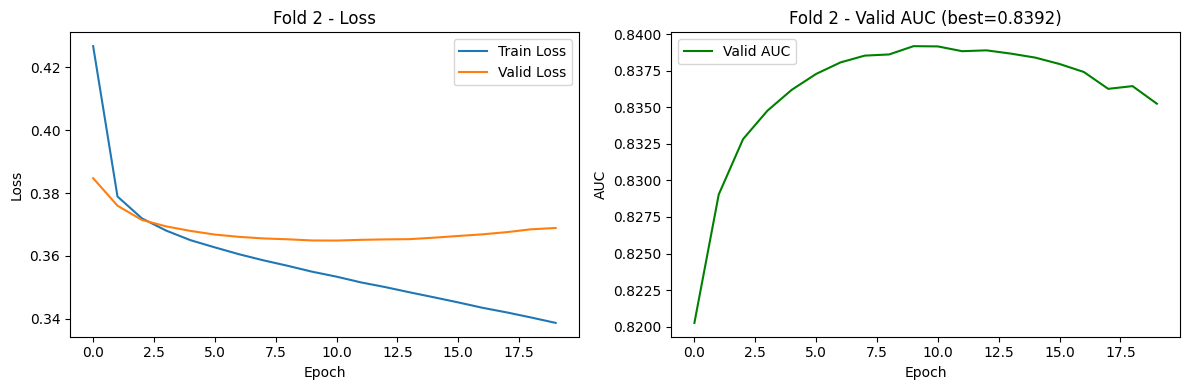

Fold 2 xong. Best valid AUC = 0.8392

FOLD 3


Epoch 1: train_loss=0.4280, val_loss=0.3835, val_auc=0.8155, val_acc=0.8354


Epoch 2: train_loss=0.3799, val_loss=0.3724, val_auc=0.8264, val_acc=0.8395


Epoch 3: train_loss=0.3728, val_loss=0.3696, val_auc=0.8293, val_acc=0.8408


Epoch 4: train_loss=0.3693, val_loss=0.3668, val_auc=0.8320, val_acc=0.8415


...

Epoch 17: train_loss=0.3442, val_loss=0.3640, val_auc=0.8349, val_acc=0.8423


Epoch 18: train_loss=0.3426, val_loss=0.3650, val_auc=0.8341, val_acc=0.8418


Epoch 19: train_loss=0.3410, val_loss=0.3658, val_auc=0.8338, val_acc=0.8420


Epoch 20: train_loss=0.3395, val_loss=0.3661, val_auc=0.8326, val_acc=0.8413


Epoch 21: train_loss=0.3378, val_loss=0.3671, val_auc=0.8325, val_acc=0.8410
Early stopping tại epoch 21


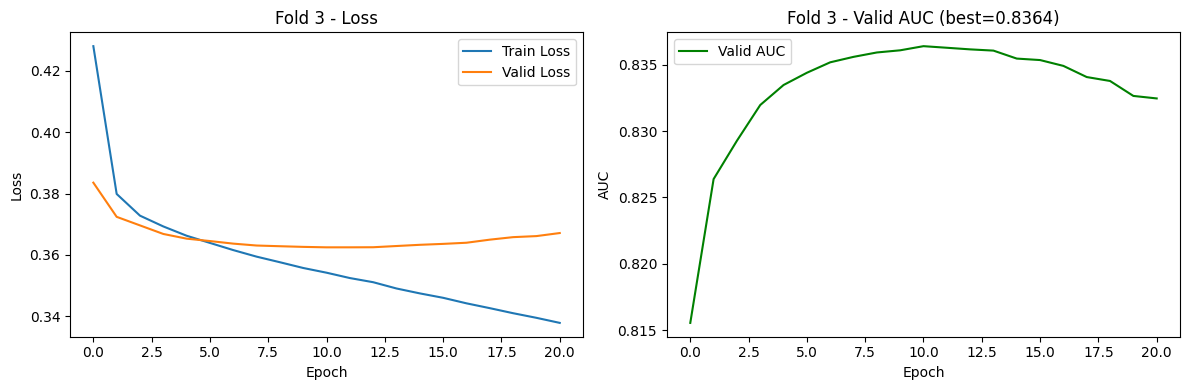

Fold 3 xong. Best valid AUC = 0.8364

FOLD 4


Epoch 1: train_loss=0.4262, val_loss=0.3847, val_auc=0.8165, val_acc=0.8339


Epoch 2: train_loss=0.3789, val_loss=0.3753, val_auc=0.8262, val_acc=0.8373


Epoch 3: train_loss=0.3718, val_loss=0.3715, val_auc=0.8298, val_acc=0.8386


Epoch 4: train_loss=0.3679, val_loss=0.3691, val_auc=0.8321, val_acc=0.8395


...

Epoch 18: train_loss=0.3415, val_loss=0.3676, val_auc=0.8341, val_acc=0.8403


Epoch 19: train_loss=0.3401, val_loss=0.3683, val_auc=0.8331, val_acc=0.8397


Epoch 20: train_loss=0.3384, val_loss=0.3692, val_auc=0.8330, val_acc=0.8398


Epoch 21: train_loss=0.3369, val_loss=0.3697, val_auc=0.8324, val_acc=0.8394


Epoch 22: train_loss=0.3354, val_loss=0.3707, val_auc=0.8318, val_acc=0.8391
Early stopping tại epoch 22


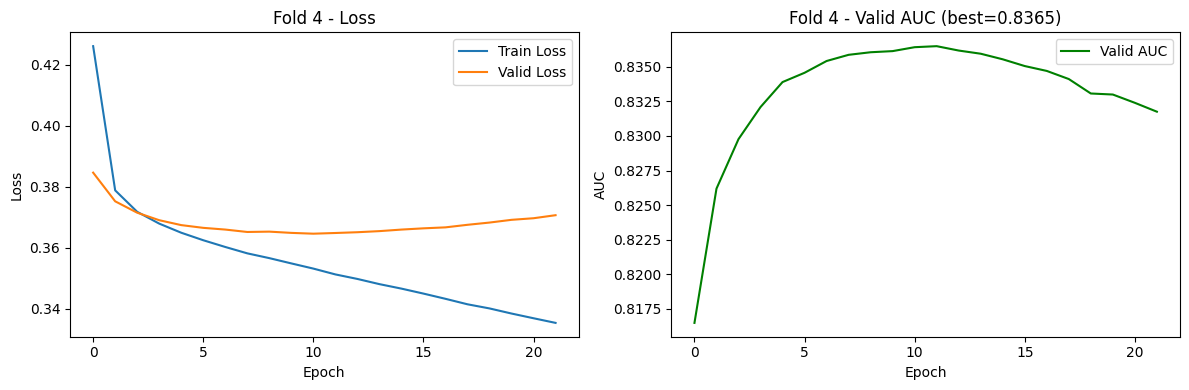

Fold 4 xong. Best valid AUC = 0.8365


In [10]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []       # giữ 5 model đã train xong, ngay trong RAM
all_histories = []        # giữ lịch sử loss/auc từng fold để vẽ biểu đồ

for i in range(5):
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    # ---- Chuẩn bị data ----
    train_dataset = DKTDataset(df_train_valid, config['num_concepts'], fold=i, is_train=True)
    valid_dataset = DKTDataset(df_train_valid, config['num_concepts'], fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    # ---- Khởi tạo model mới (random init) cho mỗi fold ----
    model = DKT(
        num_concepts=config['num_concepts'],
        embed_dim=config.get('input_dim', 100),
        hidden_dim=config.get('hidden_dim', 200),
        dropout=config.get('dropout', 0.2)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))

    # ---- Train fold này ----
    model, history = train_epoch(
        model, train_loader, valid_loader, optimizer, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )

    trained_models.append(model)     # lưu model (đã load best checkpoint) vào RAM
    all_histories.append(history)

    # ---- Vẽ biểu đồ cho fold này ----
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()

    plt.tight_layout()
    plt.show()          # hiển thị trực tiếp trong Kaggle notebook, không cần lưu file

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

In [11]:
test_dataset = DKTDataset(df_test, config['num_concepts'], fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = evaluate(model, test_loader, device, question_level=True)  # bật True nếu df_test có cột qidxs
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

Fold 0 - Test: auc=0.7842, acc=0.8169, rmse=0.3632, mae=0.2583, f1=0.8924, precision=0.8378, recall=0.9546


Fold 1 - Test: auc=0.7844, acc=0.8169, rmse=0.3631, mae=0.2571, f1=0.8926, precision=0.8366, recall=0.9566


Fold 2 - Test: auc=0.7839, acc=0.8168, rmse=0.3633, mae=0.2603, f1=0.8922, precision=0.8387, recall=0.9530


Fold 3 - Test: auc=0.7843, acc=0.8169, rmse=0.3632, mae=0.2564, f1=0.8924, precision=0.8384, recall=0.9537


Fold 4 - Test: auc=0.7843, acc=0.8168, rmse=0.3632, mae=0.2562, f1=0.8925, precision=0.8372, recall=0.9556


In [12]:
import numpy as np

metric_names = ["auc", "acc", "rmse", "mae", "f1", "precision", "recall"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")


TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.7842 ± 0.0002
ACC       : 0.8169 ± 0.0000
RMSE      : 0.3632 ± 0.0000
MAE       : 0.2577 ± 0.0015
F1        : 0.8924 ± 0.0001
PRECISION : 0.8378 ± 0.0008
RECALL    : 0.9547 ± 0.0013


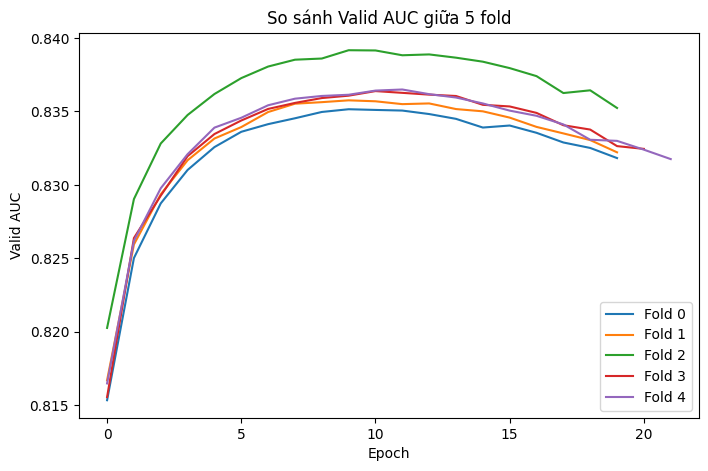

In [13]:
plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()